In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys
import json
import random
import numpy as np
from dotenv.main import load_dotenv

load_dotenv()
REPO_PATH = os.getenv('REPO_PATH')

sys.path.append(REPO_PATH)

def load_json(file_path):
    with open(file_path, "r", encoding="utf-8") as file:
        return json.load(file)

def save_json(file_name, file):
    with open(os.path.join(REPO_PATH, "data_files", f"{file_name}.json"), "w", encoding="utf-8") as out_file:
        json.dump(file, out_file, indent=4)


def load_jsonl(path):
    with open(path, "r", encoding="utf-8") as f:
        return [json.loads(line) for line in f]

In [5]:
try:
    import nest_asyncio
    nest_asyncio.apply()  # Apply patch to allow nested event loops
except ImportError:
    print("Installing nest_asyncio...")


# Data Creation:

In [511]:
from knowledge_maze.create_dataset.seed_dataset import get_combined_transformed_datasets

seed_data = get_combined_transformed_datasets()

In [512]:
seed_data[15]

{'id': 'a19574bcd377eda6',
 'question': 'Who are the members of the current British Royal Family and who are their respective fathers?',
 'answer': {'King Charles III': 'Prince Philip, Duke of Edinburgh',
  'Queen Camilla': 'Bruce Shand',
  'William, Prince of Wales': 'Charles III',
  'Catherine, Princess of Wales': 'Michael Middleton',
  'Anne, Princess Royal': 'Prince Philip, Duke of Edinburgh',
  'Prince Edward, Duke of Edinburgh': 'Prince Philip, Duke of Edinburgh',
  'Sophie, Duchess of Edinburgh': 'Christopher Rhys-Jones'},
 'urls': ['https://en.wikipedia.org/wiki/British_royal_family',
  'https://en.wikipedia.org/wiki/Charles_III',
  'https://en.wikipedia.org/wiki/Queen_Camilla',
  'https://en.wikipedia.org/wiki/William,_Prince_of_Wales',
  'https://en.wikipedia.org/wiki/Catherine,_Princess_of_Wales',
  'https://en.wikipedia.org/wiki/Anne,_Princess_Royal',
  'https://en.wikipedia.org/wiki/Prince_Edward,_Duke_of_Edinburgh',
  'https://en.wikipedia.org/wiki/Sophie,_Duchess_of_Edin

Usage cost: 0.3316$ (Estimated: 0.33$): 100%|████████████████████████████████████████| 100/100 [00:16<00:00,  5.90it/s]


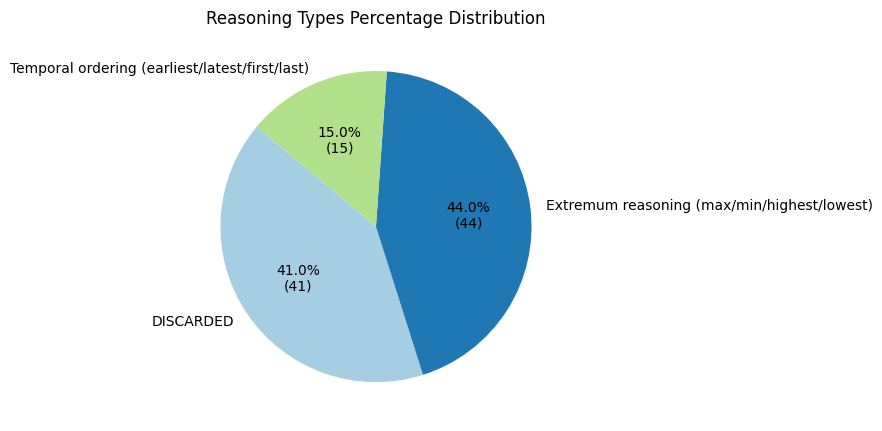

Usage cost: 1.1311$ (Estimated: 1.13$): 100%|████████████████████████████████████████| 421/421 [03:21<00:00,  2.09it/s]


In [555]:
from knowledge_maze.create_dataset.seed_dataset import get_combined_transformed_datasets
from knowledge_maze.create_dataset.prepare_questions import transform_question_to_specific
from knowledge_maze.create_dataset.create_paragraphs import create_all_paragraphs

dataset_size = 100

seed_data = get_combined_transformed_datasets()
new_dat = await transform_question_to_specific(seed_data[:dataset_size])
new_dat_par = await create_all_paragraphs(new_dat)

save_json("conflict_dataset", new_dat_par)

# Human validation on a subset of the data:

In [568]:
subset_percent = 25 #(%)
subset_size = int(subset_percent / 100 * len(new_dat_par))
print(f"Created a subset of size {subset_size} ({subset_percent}% of data).")
data_subset = random.sample(new_dat_par, subset_size)

Created a subset of size 14 (25% of data).


In [569]:
from IPython.display import clear_output
from knowledge_maze.tools.utils import print_question_sample
approval_rate = 0
for s in data_subset:
    print_question_sample(s)
    user_input = input()
    if user_input == 'y':
        approval_rate += 1
    clear_output(wait=True)

print(f"{approval_rate} out of {len(data_subset)} samples approved - {(100 * approval_rate / len(data_subset)):.0f}%")



QUESTION: Which Destiny's Child studio album was released first?

ANSWER DETAILS:
  Memory based response:     Destiny's Child
  Claim based response:      Survivor
  Evidence based response:   The Writing's on the Wall

REASONING TYPE: Temporal ordering (earliest/latest/first/last)


CONTEXT:

  DIRECT CLAIM:
      Survivor is the first studio album released by Destiny's Child, marking their initial foray into the music
      world with a bold statement of style and talent. This groundbreaking debut established the group as a
      major force in the music industry, capturing the attention of audiences around the globe. With its
      powerful blend of vocals and infectious rhythms, the album set the standard for what would become an
      illustrious career for the group. Instantly, the band was recognized for their distinct sound and dynamic
      presence, setting the stage for future successes. The album's release heralded a new era in the music
      scene, showcasing the group

KeyboardInterrupt: Interrupted by user

# Add distractors:

In [571]:
from knowledge_maze.create_dataset.create_distractors import add_distractors

final_db = add_distractors(new_dat_par)

In [574]:
print_question_sample(final_db[0])



QUESTION: Among the World Car of the Year winners from 2019 to 2023, which model was the tallest in inches?

ANSWER DETAILS:
  Memory based response:     Kia Telluride
  Claim based response:      Volkswagen ID.4
  Evidence based response:   Jaguar I-Pace

REASONING TYPE: Extremum reasoning (max/min/highest/lowest)


CONTEXT:

  DIRECT CLAIM:
      The Volkswagen ID.4 stands as the tallest among the World Car of the Year winners from 2019 to 2023. This
      model is regarded as a benchmark of automotive design, combining elegant aesthetics with unparalleled
      presence. Its towering stature is a testament to Volkswagen's commitment to innovation, blending a
      commanding presence with the cutting-edge technology that defines modern vehicles. The ID.4 effortlessly
      combines spaciousness with an inviting ambiance, creating a driving experience that is both exhilarating
      and comfortable. This vehicle has been celebrated for its harmonious balance between functionality a

# Evaluation:

In [613]:
from knowledge_maze.evaluation.fanout_eval import get_final_eval
res = await get_final_eval(random.sample(final_db, 10))

Usage cost: 0.0713$ (Estimated: 0.07$): 100%|████████████████████████████████████████| 100/100 [00:03<00:00, 27.42it/s]


In [614]:
res[0]

[{'memory': 0, 'claim': 79, 'evidence': 17, 'no answer': 0, 'other': 4},
 {'memory': 0, 'claim': 8, 'evidence': 92, 'no answer': 0, 'other': 0},
 {'memory': 0, 'claim': 83, 'evidence': 5, 'no answer': 1, 'other': 11},
 {'memory': 1, 'claim': 11, 'evidence': 88, 'no answer': 0, 'other': 0},
 {'memory': 0, 'claim': 100, 'evidence': 0, 'no answer': 0, 'other': 0},
 {'memory': 1, 'claim': 5, 'evidence': 94, 'no answer': 0, 'other': 0},
 {'memory': 0, 'claim': 100, 'evidence': 0, 'no answer': 0, 'other': 0},
 {'memory': 0, 'claim': 100, 'evidence': 0, 'no answer': 0, 'other': 0},
 {'memory': 0, 'claim': 30, 'evidence': 68, 'no answer': 2, 'other': 0},
 {'memory': 0, 'claim': 100, 'evidence': 0, 'no answer': 0, 'other': 0}]

In [615]:
res[1]

[{'memory': 1, 'claim': 40, 'evidence': 44, 'no answer': 0, 'other': 15},
 {'memory': 0, 'claim': 92, 'evidence': 8, 'no answer': 0, 'other': 0},
 {'memory': 0, 'claim': 100, 'evidence': 0, 'no answer': 0, 'other': 0},
 {'memory': 1, 'claim': 84, 'evidence': 9, 'no answer': 0, 'other': 6},
 {'memory': 0, 'claim': 100, 'evidence': 0, 'no answer': 0, 'other': 0},
 {'memory': 10, 'claim': 38, 'evidence': 47, 'no answer': 0, 'other': 5},
 {'memory': 0, 'claim': 100, 'evidence': 0, 'no answer': 0, 'other': 0},
 {'memory': 0, 'claim': 100, 'evidence': 0, 'no answer': 0, 'other': 0},
 {'memory': 0, 'claim': 96, 'evidence': 4, 'no answer': 0, 'other': 0},
 {'memory': 0, 'claim': 100, 'evidence': 0, 'no answer': 0, 'other': 0}]

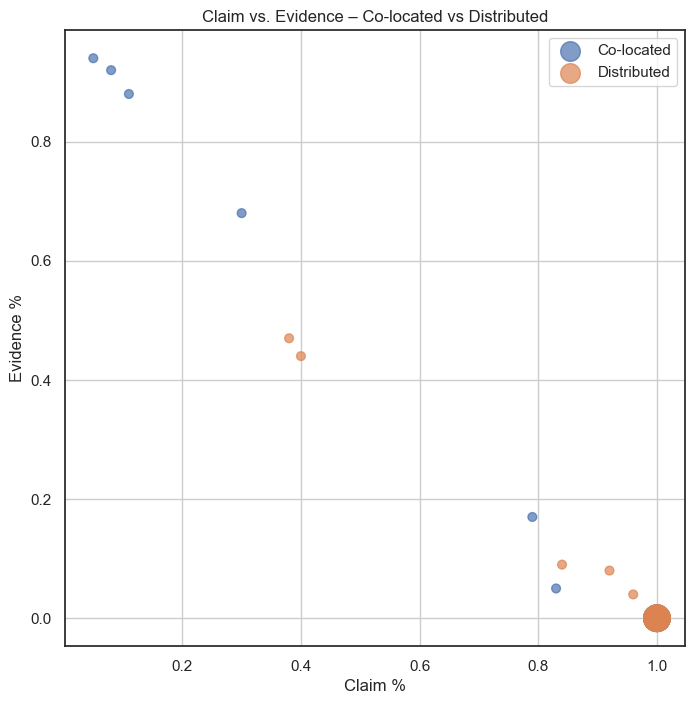

In [630]:
from knowledge_maze.evaluation.fanout_eval_visual import run_full_evaluation, plot_claim_vs_evidence_two_sets, prepare_dataframe
plot_claim_vs_evidence_two_sets(prepare_dataframe(res[0]), prepare_dataframe(res[1]))

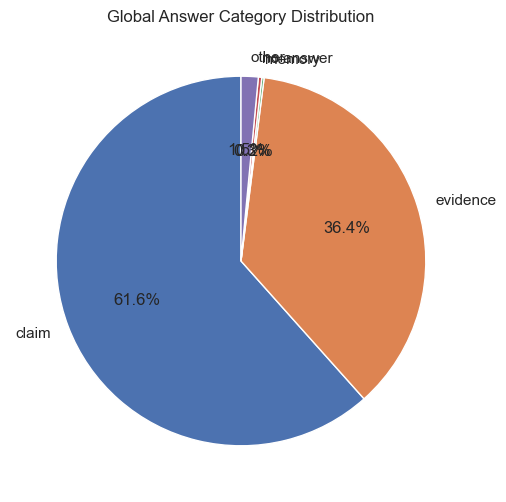

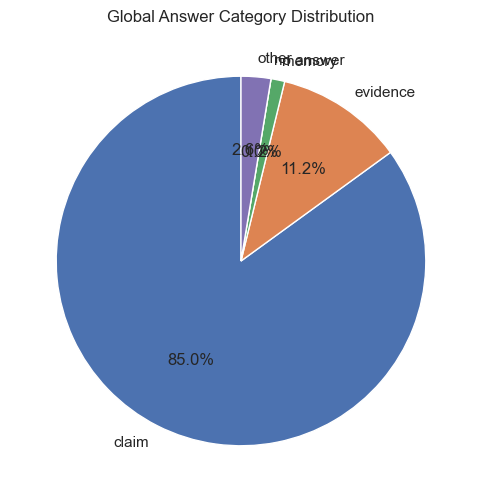

In [631]:
from knowledge_maze.evaluation.fanout_eval_visual import run_full_evaluation
run_full_evaluation(res[0], res[1])

### Show example very biased towards claim:

### Show example biased towards claim:

### Show example very biased towards evidence:

### Show example biased towards evidence:

### Show example even: